Topic modeling - Extracting meaningful insights from unstructured text data

#Preprocessing


In [ ]:
!pip install fasttext
!pip install pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 3.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pybind11-3.0.2-py3-none-any.whl.metadata (10 kB)
Using cached pybind11-3.0.2-py3-none-any.whl (310 kB)
  Created wheel for fasttext: filename=fasttext-0.9.3-cp312-cp312-linux_x86_64.whl size=4647419 sha256=abdaa37e748f6fd17d7460d384f53e8ef1500b40695ce25661ebcc60e89887e5
  Stored in directory: /root/.cache/pip/wheels/20/27/95/a7baf1b435f1cbde017cabdf1e9688526d2b0e929255a359c6
Successfully built fasttext


In [ ]:
import pandas as pd
import re
import fasttext

In [ ]:
!wget https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.bin


--2026-03-09 05:20:34--  https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.bin
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 13.249.182.62, 13.249.182.39, 13.249.182.81, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|13.249.182.62|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 131266198 (125M) [application/octet-stream]
Saving to: ‘lid.176.bin’

lid.176.bin         100%[===================>] 125.18M   329MB/s    in 0.4s    

2026-03-09 05:20:34 (329 MB/s) - ‘lid.176.bin’ saved [131266198/131266198]



In [ ]:
lang_model = fasttext.load_model("lid.176.bin")

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving sumbee_tweets.csv to sumbee_tweets.csv


In [ ]:
import pandas as pd

df = pd.read_csv("sumbee_tweets.csv")

print(df.shape)
df.head()

(5000, 2)


,ID,Text
0,9D267511-5AC1-4A06-B098-0000067B3602,Цэцэрлэгийн багш байсан гээ биз дээ энэ хүн
1,9A9C373D-A518-49BE-8334-00000848A768,Сэлэнгэ аймгийн Ерөө сумын “Буурлын даваа” гэд...
2,5DA4981A-C600-49AA-B54C-000008E09190,同じくです！餃子＋味噌汁＋野菜スティックとか納豆＋ごはん(オムライスだけとかの日もある)が限...
3,7D7A2C75-C61D-42B2-B129-00000A21F514,Цаашид явы гэж бичнэ!
4,597ECFCA-9586-4AD7-9DC1-0000108E5FD7,Олон улсын хэмжээний мастер Болдын Ганхайчид Х...


In [ ]:
df = df.dropna(subset=["Text"])

In [ ]:
def has_cyrillic(text):
    return any("\u0400" <= c <= "\u04FF" for c in text)


In [ ]:
df = df[df["Text"].apply(has_cyrillic)]

In [ ]:
df["Text"] = df["Text"].str.lower()

In [ ]:
mongolian_stopwords = {
"байна","бол","гэж","юм","энэ","тэр","байгаа","байв","байлаа",
"гэх","гэжээ","байдаг","байна","байсан","болно","гэхдээ",
"харин","мөн","бас","боловч","тухай","дээр","доор","руу",
"хийж","хийсэн","хийх","өгсөн","өгөх","авсан","авах",
"нь","ийн","ын","д","аас","ээс"
}
def remove_stopwords(text):
    words = text.split()
    words = [w for w in words if w not in mongolian_stopwords]
    return " ".join(words)

In [ ]:
import re

def clean_text(text):

    text = re.sub(r"http\S+", "", text)      # links
    text = re.sub(r"[@#]", "", text)         # strip symbols, keep hashtag/mention words
    text = re.sub(r"[^\w\s\u0400-\u04FF]", " ", text)    #emoji

    text = re.sub(r"[^\w\s]", " ", text)     # punctuation

    text = re.sub(r"\s+", " ", text)         # extra spaces

    return text.strip()

In [ ]:
df["clean_text"] = df["Text"].apply(clean_text)


In [ ]:
df["clean_text"] = df["clean_text"].apply(remove_stopwords)

# Topic modeling


In [ ]:
!pip install sentence-transformers

In [ ]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
"sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
)

docs = df["clean_text"].tolist()

embeddings = model.encode(docs, show_progress_bar=True)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/136 [00:00<?, ?it/s]

In [ ]:
!pip install bertopic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 7.1 MB/s eta 0:00:00


In [ ]:
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer

# Pass stopwords to CountVectorizer so topics are not filled with common Mongolian words
vectorizer_model = CountVectorizer(stop_words=list(mongolian_stopwords))

topic_model = BERTopic(language="multilingual", vectorizer_model=vectorizer_model)

topics, probs = topic_model.fit_transform(docs)
topic_model.get_topic_info()

/usr/local/lib/python3.12/dist-packages/hdbscan/robust_single_linkage_.py:175: SyntaxWarning: invalid escape sequence '\{'
  $max \{ core_k(a), core_k(b), 1/\alpha d(a,b) \}$.


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/526 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [37]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,1986,-1_хүн_дээ_уу_байх,"[хүн, дээ, уу, байх, гээд, шиг, шүү, нэг, чинь...",[аюултай болж бна хамтарсан засаг ямар аюултай...
1,0,170,0_хүн_зөв_еөк_хүнээс,"[хүн, зөв, еөк, хүнээс, өөр, чамайг, байх, муу...",[атаархал чамайг өөрт зүйлсээ умартахад л хүрг...
2,1,144,1_монгол_монголын_монголд_улсын,"[монгол, монголын, монголд, улсын, дэлхийн, хү...",[н хүрэлбаатар эмчийг маш сайн мэдэх хүний нэг...
3,2,105,2_машин_замын_зам_тээврийн,"[машин, замын, зам, тээврийн, түгжрэл, хотын, ...",[төмөр зам ба хурдны замууд хотыг хуваадаг төм...
4,3,80,3_амьтан_нохой_хиамчин_увсын,"[амьтан, нохой, хиамчин, увсын, хиамчид, зарна...",[уянгалах юунд хэрэгтэй бэ та нар эвсэж лаларт...
...,...,...,...,...,...
68,67,11,67_утсаа_суманд_залгавал_дуудлага,"[утсаа, суманд, залгавал, дуудлага, гар, сүлжэ...",[6 үяарч сандарсан үйлчлүүлэгч утсаа унаанд чи...
69,68,10,68_коммунист_коммунистууд_комунист_гэвч,"[коммунист, коммунистууд, комунист, гэвч, боло...",[боловсролгүй маанаг ес ыг өөр нэг арай боловс...
70,69,10,69_гавъяат_g20_улсын_өмнөд,"[гавъяат, g20, улсын, өмнөд, хэнтий, агуу, col...",[тува улсын гавъяат буриад улсын гавъяат халим...
71,70,10,70_сэтгүүлч_ан_ман_үү,"[сэтгүүлч, ан, ман, үү, уу, , , , , ]","[ман, ан уу, сэтгүүлч үү]"


# NER

In [ ]:
from transformers import pipeline

ner = pipeline(
    "ner",
    model="nomio4640/mongolian-bert-ner",
    tokenizer="nomio4640/mongolian-bert-ner",
    aggregation_strategy="simple"
)

ner("Улаанбаатар хотод Бат-Эрдэнэ ажилладаг")

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/21.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

[{'entity_group': 'LOC',
  'score': np.float32(0.6613636),
  'word': 'Улаанбаатар',
  'start': 0,
  'end': 11},
 {'entity_group': 'PER',
  'score': np.float32(0.98938555),
  'word': 'Бат',
  'start': 17,
  'end': 21}]

In [ ]:
def clean_entities(entities):

    cleaned = []

    for ent in entities:
        word = ent["word"]

        # subword token
        if word.startswith("##") and len(cleaned) > 0:
            cleaned[-1]["word"] += word.replace("##","")
        else:
            cleaned.append(ent)

    return cleaned

In [ ]:
df["entitiesMN"] = df["clean_text"].apply(ner)

In [ ]:
df["entities_cleanMN"] = df["entitiesMN"].apply(clean_entities)

In [ ]:
from collections import Counter

# бүх entity-г нэг list болгох
all_entities = []
for row in df["entities_cleanMN"]:
    for ent in row:
        all_entities.append((ent["word"], ent["entity_group"]))

# төрөлөөр нь ялгах
per = [w for w,t in all_entities if t == "PER"]
org = [w for w,t in all_entities if t == "ORG"]
loc = [w for w,t in all_entities if t == "LOC"]

# хамгийн их давтагдсан 10
top_per = Counter(per).most_common(20)
top_org = Counter(org).most_common(20)
top_loc = Counter(loc).most_common(20)

print("Top 10 PERSON:")
for w,c in top_per:
    print(w, c)

print("\nTop 10 ORG:")
for w,c in top_org:
    print(w, c)

print("\nTop 10 LOC:")
for w,c in top_loc:
    print(w, c)

Top 10 PERSON:
 49
ням 19
энх 7
элбэг 6
хүрэл 4
дорж 4
цогт 4
нян 4
номтой 3
бат 3
алтан 3
бямба 2
ж 2
сайхан 2
сүх 2
н 2
ч 2
ой 2
эрдэнэ 2
чин 2

Top 10 ORG:
 26
inews mn 6
монголбанк 4
ikon  4
хаан 2
24tsag mn 2
монгол 2
starlink 1
ubn mn 1
сооб 1
ил 1
ко 1
оюу толгой 1
толгойн 1
ман 1
шинжлэх ухааны академи 1
in  1
банк 1
шунхлай 1
к лени 1

Top 10 LOC:
 38
монгол 35
монголын 19
улаанбаатар 12
монголд 8
франц 6
улаан 5
хятадын 5
америк 4
толгой 4
богд 3
с 3
т 3
украин 3
ар 3
хангай 3
турк 2
японы 2
баян 2
казах 2


Multilingual

In [ ]:
from transformers import pipeline

ner = pipeline(
    "ner",
    model="Davlan/bert-base-multilingual-cased-ner-hrl",
    aggregation_strategy="simple"
)

df["entities"] = df["clean_text"].apply(ner)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/709M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: Davlan/bert-base-multilingual-cased-ner-hrl
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/264 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [ ]:
df["entities_clean"] = df["entities"].apply(clean_entities)

In [38]:
for row in df["entities_clean"].head(20):
    for ent in row:
        print(ent["word"], ent["entity_group"])

сэлэнгэ аймгийн LOC
ерөө сумөө LOC
хэнтий LOC
хэнтий аймгийн LOC
##онгор LOC
богдын гол LOC
богдын голын LOC
завхан аймгийн LOC
ээ LOC
австрали LOC
монгол улсын LOC
монгол LOC


In [ ]:
df.to_excel("tweets_with_entities.xlsx", index=False)

In [ ]:
from google.colab import files
files.download("tweets_with_entities.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from collections import Counter

# бүх entity-г нэг list болгох
all_entities = []
for row in df["entities_clean"]:
    for ent in row:
        all_entities.append((ent["word"], ent["entity_group"]))

# төрөлөөр нь ялгах
per = [w for w,t in all_entities if t == "PER"]
org = [w for w,t in all_entities if t == "ORG"]
loc = [w for w,t in all_entities if t == "LOC"]

# хамгийн их давтагдсан 10
top_per = Counter(per).most_common(20)
top_org = Counter(org).most_common(20)
top_loc = Counter(loc).most_common(20)

print("Top 10 PERSON:")
for w,c in top_per:
    print(w, c)

print("\nTop 10 ORG:")
for w,c in top_org:
    print(w, c)

print("\nTop 10 LOC:")
for w,c in top_loc:
    print(w, c)

Top 10 PERSON:
чингис хаан 3
элбэгдоржий 3
амарбаясгалан 2
элбэгдорж 2
пут 2
дэвид перкин 1
наранбаяр 1
випашяна бясалгал 1
radnaabazar 1
лхагвасүрэн 1
вячеслав 1
балмад 1
андрей белоу 1
ухнааг 1
эмомали рахмон 1
##гис 1
##агаад 1
жоржеску 1
батболд 1
##м 1

Top 10 ORG:
g20 2
мимо агр 2
##ио тинто монголын 1
рио тинто монголын засгийн газар 1
starlink 1
inews 1
bbc 1
##ьянмарын сан 1
русал риоо 1
cmm 1
штайнколe х 1
монголбанк 1
монгол улсын шинжлэх ухааны академи 1
##ын 1
дснк ленин клуб 1
эрхүүгийн центр 1
хаан 1
монгол улсын засгийн газарсү 1
##ционной безопасности 1
у 1

Top 10 LOC:
орос 70
монгол 32
монгол улсын 28
##онгол 22
монгол улс 20
улаанбаатар 19
гадаад 13
##ол 12
о 9
америк 8
монголд 7
хятад 6
##агаад 5
оросын 5
хята 4
сүхбаатар аймгийн 3
вьетнам 3
хөвсгөл 3
гадаа 3
улаанбаатар хот 3


# Sentiment analysis

In [ ]:
from transformers import pipeline

sentiment = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment"
)

df["sentiment"] = df["Text"].apply(sentiment)

In [ ]:
df.to_excel("tweets_with_entities.xlsx", index=False)

In [ ]:
from google.colab import files
files.download("tweets_with_entities.xlsx")

# Network analysis


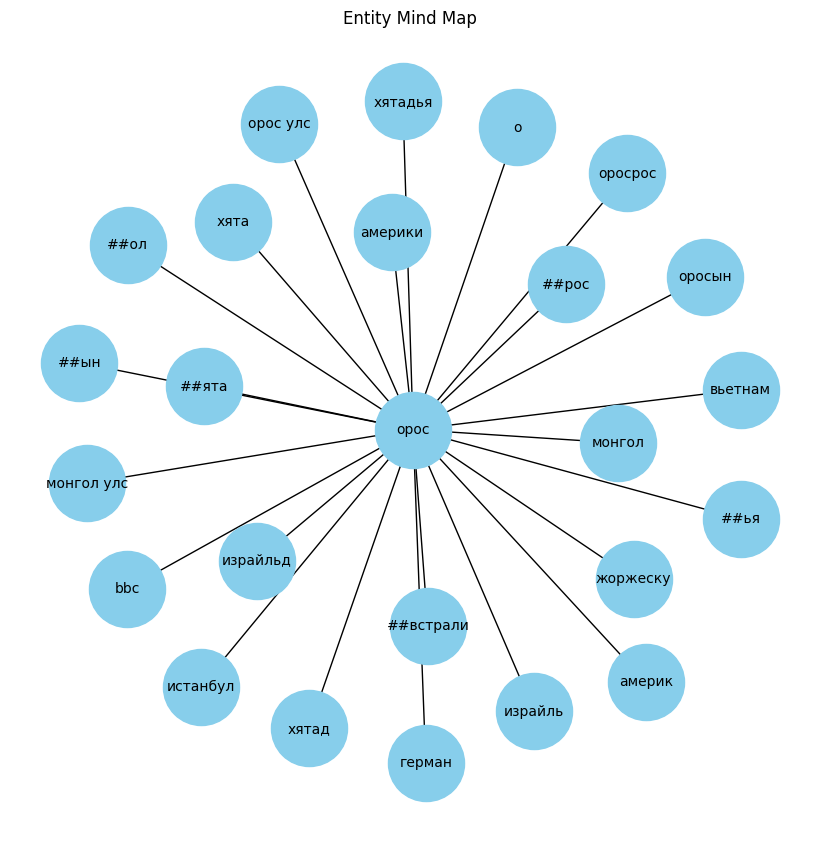

In [ ]:
!pip install pyvis community louvain community-louvain
from collections import Counter
import networkx as nx
from pyvis.network import Network
import community.community_louvain as community_louvain
import IPython

# Collect all entities with their types
all_entities = []
entity_types = {}
for row in df["entities_clean"]:
    for ent in row:
        all_entities.append(ent["word"])
        entity_types[ent["word"]] = ent["entity_group"]

# Top most frequent entities
top_entities = [e for e,_ in Counter(all_entities).most_common(50)]

G = nx.Graph()

# Build Co-occurrence network
for row in df["entities_clean"]:
    words = [ent["word"] for ent in row if ent["word"] in top_entities]
    for i in range(len(words)):
        for j in range(i+1, len(words)):
            if G.has_edge(words[i], words[j]):
                G[words[i]][words[j]]['weight'] += 1
            else:
                G.add_edge(words[i], words[j], weight=1)

# Calculate Degree Centrality for node sizes
centrality = nx.degree_centrality(G)

# Detect Communities (Clusters)
partition = community_louvain.best_partition(G)

# Initialize PyVis Network
net = Network(notebook=True, width='100%', height='800px', bgcolor='#222222', font_color='white', select_menu=True, filter_menu=True)

# Entity type to color mapping
color_map = {'PER': '#FFD700', 'ORG': '#87CEFA', 'LOC': '#98FB98', 'MISC': '#DDA0DD'}

for node in G.nodes():
    node_type = entity_types.get(node, 'MISC')
    group_id = partition.get(node, 0)
    net.add_node(node, 
                 label=node,
                 title=f'Type: {node_type}\nCommunity: {group_id}',
                 size=centrality[node] * 300, # dynamic sizing
                 color=color_map.get(node_type, '#DDA0DD'),
                 group=group_id)

for edge in G.edges(data=True):
    net.add_edge(edge[0], edge[1], value=edge[2]['weight'])

net.repulsion(node_distance=200, spring_length=200)
net.show('network_analysis.html')
IPython.display.HTML('network_analysis.html')

In [ ]:
connections = Counter()

for row in df["entities"]:
    words = [ent["word"] for ent in row]

    if center in words:
        for w in words:
            if w != center:
                connections[w] += 1

top_connections = connections.most_common(10)

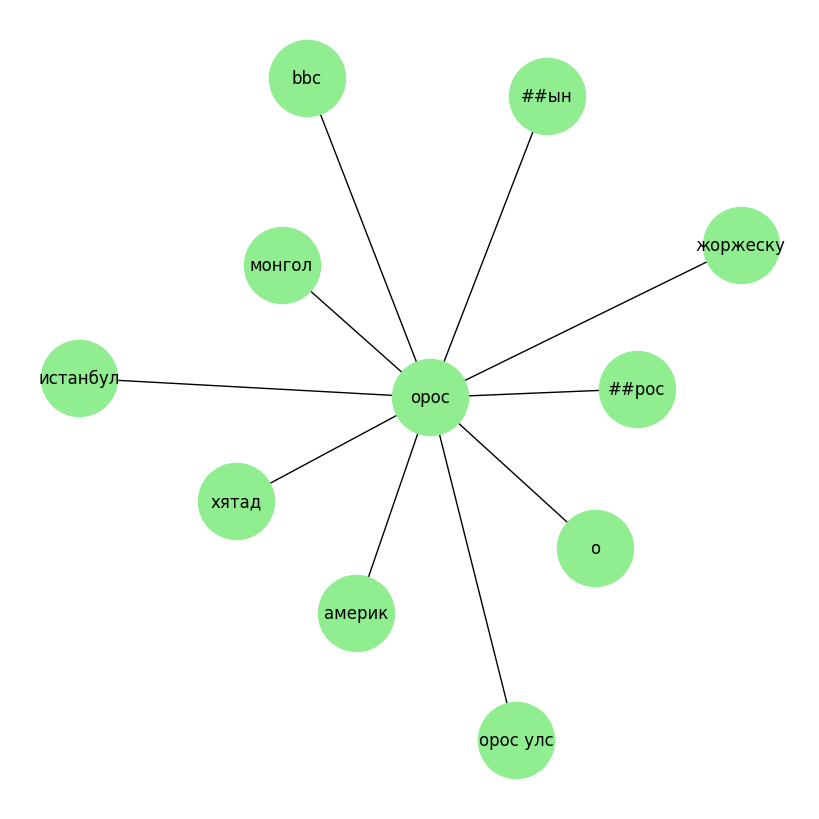

In [ ]:
G = nx.Graph()

for word,count in top_connections:
    G.add_edge(center, word, weight=count)

plt.figure(figsize=(8,8))

pos = nx.spring_layout(G)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color="lightgreen"
)

plt.show()

# NER mongolian bert ner - train

In [ ]:
import os
os.kill(os.getpid(), 9)

In [ ]:
!pip install -q "numpy>=1.26.0,<2.0.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 104.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python-headless 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
cupy-cuda12x 14.0.1 requires numpy<2.6,>=2.0, but you have numpy 1.26.4 which is incompatible.
shap 0.50.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
opencv-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
tobler 0.13.0 requires numpy>=2.0, but 

In [ ]:
!pip install -q transformers==4.41.2 datasets==2.20.0 accelerate==0.32.1 seqeval

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 4.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 547.8/547.8 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.1/314.1 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.1/316.1 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 37.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.5.0 which is incompatible.


In [ ]:
!pip install -q transformers datasets accelerate seqeval

In [ ]:
!git clone https://github.com/enod/mongolian-bert-ner.git

Cloning into 'mongolian-bert-ner'...
remote: Enumerating objects: 200, done.
remote: Total 200 (delta 0), reused 0 (delta 0), pack-reused 200 (from 1)
Receiving objects: 100% (200/200), 2.04 MiB | 8.79 MiB/s, done.
Resolving deltas: 100% (90/90), done.


In [ ]:
%cd mongolian-bert-ner

/content/mongolian-bert-ner


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "tugstugi/bert-base-mongolian-cased"
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/46.0 [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/1.00M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/16.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

In [ ]:
def read_conll(path):

    sentences = []
    labels = []

    words = []
    tags = []

    with open(path) as f:
        for line in f:

            line = line.strip()

            if line == "":
                if words:
                    sentences.append(words)
                    labels.append(tags)

                words = []
                tags = []

            else:
                parts = line.split()

                word = parts[0]
                tag = parts[-1]

                words.append(word)
                tags.append(tag)

    return sentences, labels

In [ ]:
train_texts, train_labels = read_conll("data/train.txt")
val_texts, val_labels = read_conll("data/valid.txt")
test_texts, test_labels = read_conll("data/test.txt")

In [ ]:
print(train_texts[0])
print(train_labels[0])

['Д.Гантулга', 'гишүүн', 'улайм', 'цайм', '"Тэндээс', 'би', 'бандаашаа', 'өмсөөд', 'гарсан"', 'гэх', 'мэдээллийг', 'олон', 'нийтийн', 'өмнө', 'хийчихээд', 'байхад', 'шударга', 'шүүх', 'юу', 'ч', 'болоогүй', 'мэт', 'хаяхгүй', 'байлгүй', 'дээ.']
['B-PER', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


In [ ]:
unique_labels = set()

for sent in train_labels:
    for l in sent:
        unique_labels.add(l)

label_list = sorted(list(unique_labels))

label2id = {l:i for i,l in enumerate(label_list)}
id2label = {i:l for i,l in enumerate(label_list)}

print(label_list)

['B-LOC', 'B-MISC', 'B-ORG', 'B-PER', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O']


In [ ]:
from datasets import Dataset

train_dataset = Dataset.from_dict({
    "tokens": train_texts,
    "ner_tags": train_labels
})

val_dataset = Dataset.from_dict({
    "tokens": val_texts,
    "ner_tags": val_labels
})

test_dataset = Dataset.from_dict({
    "tokens": test_texts,
    "ner_tags": test_labels
})

ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

In [ ]:
def tokenize_and_align_labels(example):

    tokenized_inputs = tokenizer(
        example["tokens"],
        truncation=True,
        padding="max_length",
        max_length=128,
        is_split_into_words=True
    )

    word_ids = tokenized_inputs.word_ids()

    labels = []
    previous_word_idx = None

    for word_idx in word_ids:

        if word_idx is None:
            labels.append(-100)

        elif word_idx != previous_word_idx:
            labels.append(label2id[example["ner_tags"][word_idx]])

        else:
            labels.append(-100)

        previous_word_idx = word_idx

    tokenized_inputs["labels"] = labels

    return tokenized_inputs

In [ ]:
train_dataset = train_dataset.map(
    tokenize_and_align_labels,
    remove_columns=["tokens","ner_tags"]
)

val_dataset = val_dataset.map(
    tokenize_and_align_labels,
    remove_columns=["tokens","ner_tags"]
)

In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./ner_model",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    evaluation_strategy="epoch"
)

In [ ]:
!

In [ ]:
import transformers
import accelerate
import datasets

print("transformers:", transformers.__version__)
print("accelerate:", accelerate.__version__)
print("datasets:", datasets.__version__)

In [ ]:
from transformers import AutoModelForTokenClassification

model = AutoModelForTokenClassification.from_pretrained(
    "tugstugi/bert-base-mongolian-cased",
    num_labels=len(label_list),
    id2label=id2label,
    label2id=label2id
)

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer
)

In [ ]:
trainer.train()

In [ ]:
from transformers import pipeline

ner = pipeline(
    "ner",
    model="./ner_model",
    tokenizer=tokenizer
)

ner("АТГ-аас мэдэгдэл хийлээ")

In [ ]:
from transformers import pipeline

ner = pipeline(
    "ner",
    model="ner_model",
    tokenizer=tokenizer
)

ner("АТГ-аас мэдэгдэл хийлээ")